> **In this repository.** **Preliminary.** Exploratory analysis of an early 10,000-photo sample (native vs. introduced plants of the American Southwest): label counts, species frequencies, species found in both pools, and image sizes, orientations and aspect ratios. The final dataset is built by `src/invasive_clf/data/build_dataset.py`. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


# Exploratory data analysis for the iNaturalist dataset

This is a sample of 10,000 American southwest plant photos we retrieved from iNaturalist.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("/content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset/")
META_CSV = DATA_DIR / "metadata_all.csv"

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)

LABEL_ORDER = ["native", "introduced"]
LABEL_COLOR = {"native": "#2a78d6", "introduced": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

We load the metadata:

In [7]:
df = pd.read_csv(META_CSV)
print(df.shape)
df.head(3)

(10000, 25)


,label,image_path,observation_id,observation_url,scientific_name,common_name,taxon_id,rank,establishment_means,establishment_place,...,observed_on,quality_grade,num_identification_agreements,observer,annotations,photo_id,photo_url,photo_license,photo_attribution,n_photos_in_observation
0,introduced,images/introduced/406551036_746954417.jpg,406551036,https://www.inaturalist.org/observations/40655...,Verbascum thapsus,great mullein,59029,species,introduced,NaN,...,2026-10-04,research,1,ycdel,[],746954417,https://inaturalist-open-data.s3.amazonaws.com...,cc-by-nc,"(c) ycdel, some rights reserved (CC BY-NC)",1
1,introduced,images/introduced/406548450_746949072.jpg,406548450,https://www.inaturalist.org/observations/40654...,Verbascum thapsus,great mullein,59029,species,introduced,NaN,...,2026-07-19,research,1,cmkfreeman,[],746949072,https://inaturalist-open-data.s3.amazonaws.com...,cc-by-nc,"(c) cmkfreeman, some rights reserved (CC BY-NC)",1
2,introduced,images/introduced/406500331_746855613.jpg,406500331,https://www.inaturalist.org/observations/40650...,Lactuca serriola,prickly lettuce,53107,species,introduced,NaN,...,2026-09-23,research,1,jacobhoggan,[],746855613,https://inaturalist-open-data.s3.amazonaws.com...,cc-by-nc,"(c) jacobhoggan, some rights reserved (CC BY-NC)",1


We count each "label" category and verify that images are in the correct folders. We also observe zero duplicate IDs.

In [8]:
print("Rows per label:")
print(df["label"].value_counts().to_string(), end="\n\n")

print("Duplicate photo_id:      ", df["photo_id"].duplicated().sum())
print("Duplicate observation_id:", df["observation_id"].duplicated().sum())

missing = ~df["image_path"].map(lambda p: (DATA_DIR / p).exists())
print("Rows whose image file is missing on disk:", int(missing.sum()))

folder = df["image_path"].str.split("/").str[1]
print("Rows where folder != label:", int((folder != df["label"]).sum()))

Rows per label:
label
introduced    5000
native        5000

Duplicate photo_id:       0
Duplicate observation_id: 0
Rows whose image file is missing on disk: 0
Rows where folder != label: 0


We observe that most scientific names fall under the "species" rank but some fall under variety, subspecies, etc.

In [9]:
print("Taxonomic rank of each row:")
print(df["rank"].value_counts().to_string(), end="\n\n")

Taxonomic rank of each row:
rank
species       9707
variety        161
subspecies     117
hybrid           7
genus            5
complex          3



We compare the "label" target with the "establishment_means" label. Note that some images with label "introduced" have an establishment_means of "native". Also note that both label categories have rows with missing establishment_means values.

In [11]:
print("Label vs. iNaturalist establishment_means:")
pd.crosstab(df["label"], df["establishment_means"].fillna("(none)"), margins=True)

Label vs. iNaturalist establishment_means:


establishment_means,(none),endemic,introduced,native,All
label,,,,,
introduced,94,11,4529,366,5000
native,205,499,0,4296,5000
All,299,510,4529,4662,10000


## Species distribution

We count the number of distinct species in total and within each pool. Observing the distribution of species counts, we see that more than 25% of species in the current sample only have a single row. Other species may be missing entirely.

In [12]:
species_counts = df["scientific_name"].value_counts()
species_by_label = (
    df.groupby(["scientific_name", "label"]).size()
      .unstack("label", fill_value=0)
      .reindex(columns=LABEL_ORDER)
)
species_by_label["total"] = species_by_label.sum(axis=1)
species_by_label = species_by_label.sort_values("total", ascending=False)

print("Distinct scientific names overall:", df["scientific_name"].nunique())
print("Distinct scientific names per pool:")
print(df.groupby("label")["scientific_name"].nunique().reindex(LABEL_ORDER).to_string(), end="\n\n")

print("Photos per species (overall):")
print(species_counts.describe())

Distinct scientific names overall: 1960
Distinct scientific names per pool:
label
native        1410
introduced     573

Photos per species (overall):
count    1960.000000
mean        5.102041
std        10.438463
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max       100.000000
Name: count, dtype: float64


### Species appearing in both pools

Here we observe that species tend to be either entirely native or entirely introduced, with some having rows in both categories like Solanum elaeagnifolium, which is native to the southwestern deserts but a weed in California.

In [ ]:
print("Top 25 species by photo count, split across pools:")
species_by_label.head(25)

Top 25 species by photo count, split across pools:


label,native,introduced,total
scientific_name,,,
Convolvulus arvensis,0,100,100
Ricinus communis,0,100,100
Verbascum thapsus,0,100,100
Nicotiana glauca,0,100,100
Echinocereus relictus,100,0,100
Datura wrightii,100,0,100
Tribulus terrestris,0,99,99
Echinomastus johnsonii,80,0,80
Medicago sativa,0,78,78


In [13]:
in_both = species_by_label[(species_by_label["native"] > 0) & (species_by_label["introduced"] > 0)].copy()
in_both["share_introduced"] = (in_both["introduced"] / in_both["total"]).round(2)

print(f"Species appearing in BOTH pools: {len(in_both)} of {len(species_by_label)} "
      f"({len(in_both) / len(species_by_label):.1%} of species names)")
print(f"Photos belonging to those species: {int(in_both['total'].sum())} of {len(df)} "
      f"(native pool: {int(in_both['native'].sum())}, introduced pool: {int(in_both['introduced'].sum())})")
print()
print("Species only in native pool:    ", int((species_by_label['introduced'] == 0).sum()), "species")
print("Species only in introduced pool:", int((species_by_label['native'] == 0).sum()), "species")

Species appearing in BOTH pools: 23 of 1960 (1.2% of species names)
Photos belonging to those species: 228 of 10000 (native pool: 103, introduced pool: 125)

Species only in native pool:     1387 species
Species only in introduced pool: 550 species


In [14]:
common_names = df.drop_duplicates("scientific_name").set_index("scientific_name")["common_name"]
in_both.insert(0, "common_name", common_names.reindex(in_both.index))
in_both.sort_values("total", ascending=False)

label,common_name,native,introduced,total,share_introduced
scientific_name,,,,,
Solanum elaeagnifolium,silverleaf nightshade,36,24,60,0.40
Solanum rostratum,buffalo-bur,4,22,26,0.85
Verbesina encelioides,cowpen daisy,9,11,20,0.55
Oenothera speciosa,Pinkladies,1,16,17,0.94
Parkinsonia aculeata,Mexican palo verde,1,15,16,0.94
Grindelia squarrosa,Curlycup Gumweed,9,3,12,0.25
Helianthus annuus,Common Sunflower,10,1,11,0.09
Gaillardia pulchella,firewheel,3,6,9,0.67
Penstemon palmeri,Palmer's penstemon,3,5,8,0.62


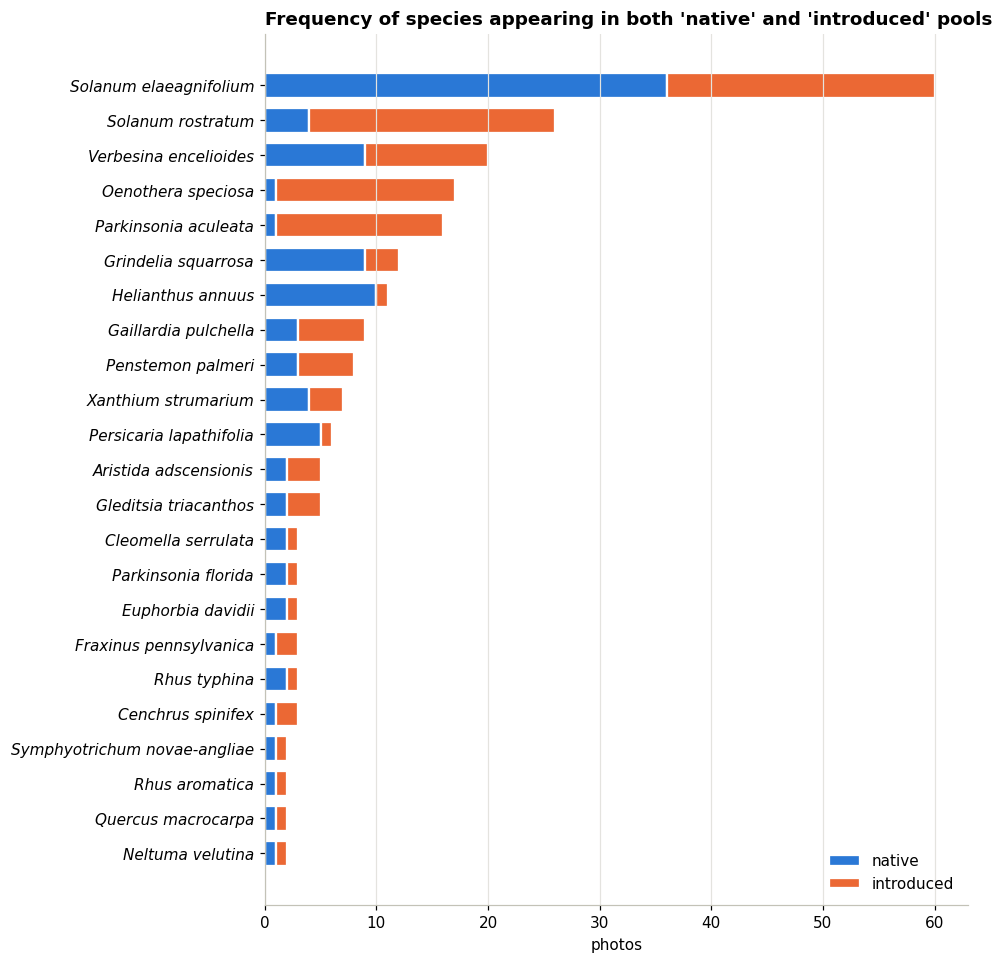

In [ ]:
plot_df = in_both.sort_values("total", ascending=True)
fig, ax = plt.subplots(figsize=(9, 0.32 * len(plot_df) + 1.5))
y = np.arange(len(plot_df))
left = np.zeros(len(plot_df))
for lab in LABEL_ORDER:
    vals = plot_df[lab].values
    ax.barh(y, vals, left=left, height=0.7, color=LABEL_COLOR[lab], edgecolor="white", linewidth=1.5, label=lab)
    left = left + vals
ax.set_yticks(y)
ax.set_yticklabels(plot_df.index, fontstyle="italic")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("photos")
ax.set_title("Frequency of species appearing in both 'native' and 'introduced' pools")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

We observe that the species appearing in both pools always have an establishment_means of "native".

In [ ]:
shared = df[df["scientific_name"].isin(in_both.index)]
print("Shared species: label vs iNat establishment_means")
display(pd.crosstab(shared["label"], shared["establishment_means"].fillna("(none)"), margins=True))

geo = (shared.groupby(["scientific_name", "label"])
             .agg(n=("photo_id", "size"),
                  lat_mean=("latitude", "mean"),
                  lon_mean=("longitude", "mean"))
             .round(2)
             .unstack("label"))
geo.columns = [f"{a}_{b}" for a, b in geo.columns]
geo.sort_values("n_introduced", ascending=False).head(10)

Shared species: label vs iNat establishment_means


establishment_means,native,All
label,,
introduced,125,125
native,103,103
All,228,228


,n_introduced,n_native,lat_mean_introduced,lat_mean_native,lon_mean_introduced,lon_mean_native
scientific_name,,,,,,
Solanum elaeagnifolium,24,36,33.85,34.02,-117.82,-108.82
Solanum rostratum,22,4,38.92,33.39,-105.88,-108.13
Oenothera speciosa,16,1,34.72,34.60,-118.41,-112.33
Parkinsonia aculeata,15,1,33.92,31.58,-115.86,-110.31
Verbesina encelioides,11,9,34.25,35.77,-115.72,-106.62
Gaillardia pulchella,6,3,37.95,37.63,-114.88,-105.64
Penstemon palmeri,5,3,38.60,36.10,-107.78,-114.15
Aristida adscensionis,3,2,32.24,34.62,-110.88,-111.74
Gleditsia triacanthos,3,2,37.80,33.59,-116.34,-108.38


We plot the distribution of species appearing in both pools by geographic location.

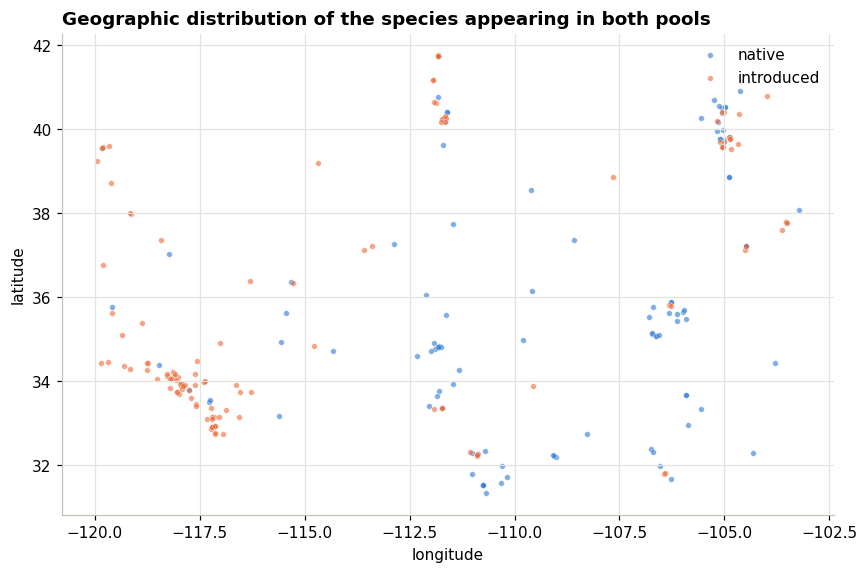

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
for lab in LABEL_ORDER:
    sub = shared[shared["label"] == lab]
    ax.scatter(sub["longitude"], sub["latitude"], s=14, alpha=0.6, color=LABEL_COLOR[lab],
               edgecolor="white", linewidth=0.4, label=lab)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Geographic distribution of the species appearing in both pools")
ax.grid(axis="x", visible=True)
ax.legend(frameon=False)
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## Image dimensions

We read the pixel dimensions of every image and cache to `image_dims.csv`.

In [ ]:
CACHE = DATA_DIR / "image_dims.csv"

if CACHE.exists():
    dims = pd.read_csv(CACHE)
else:
    records = []
    for p in df["image_path"]:
        with Image.open(DATA_DIR / p) as im:
            w, h = im.size
            fmt = im.format
        records.append((p, w, h, fmt))
    dims = pd.DataFrame(records, columns=["image_path", "width", "height", "format"])
    dims.to_csv(CACHE, index=False)

df = df.drop(columns=[c for c in ["width", "height", "format"] if c in df.columns]).merge(dims, on="image_path", how="left")
assert df["width"].notna().all()

df["longest_side"] = df[["width", "height"]].max(axis=1)
df["shortest_side"] = df[["width", "height"]].min(axis=1)
df["aspect_ratio"] = df["width"] / df["height"]   # > 1 landscape, < 1 portrait
df["orientation"] = np.select(
    [df["width"] > df["height"], df["width"] < df["height"]],
    ["landscape", "portrait"],
    default="square"
)

print("Image formats:", df["format"].value_counts().to_dict())
df[["image_path", "width", "height", "longest_side", "orientation"]].head()

Image formats: {'JPEG': 10000}


,image_path,width,height,longest_side,orientation
0,images/introduced/406551036_746954417.jpg,375,500,500,portrait
1,images/introduced/406548450_746949072.jpg,281,500,500,portrait
2,images/introduced/406500331_746855613.jpg,281,500,500,portrait
3,images/introduced/406497946_746852335.jpg,281,500,500,portrait
4,images/introduced/406493309_746843591.jpg,375,500,500,portrait


We plot the frequency of image dimensions.

In [ ]:
dim_counts = (df.groupby(["width", "height"]).size()
                .sort_values(ascending=False)
                .rename("n_photos"))
print("Distinct (width, height) pairs:", len(dim_counts))
print()
print("Most common dimensions:")
top = dim_counts.head(15).reset_index()
top["share"] = (top["n_photos"] / len(df)).map("{:.1%}".format)
top

Distinct (width, height) pairs: 328

Most common dimensions:


,width,height,n_photos,share
0,375,500,5314,53.1%
1,281,500,1616,16.2%
2,500,375,933,9.3%
3,500,333,487,4.9%
4,376,500,474,4.7%
5,500,500,192,1.9%
6,500,281,190,1.9%
7,333,500,68,0.7%
8,231,500,53,0.5%
9,500,334,33,0.3%


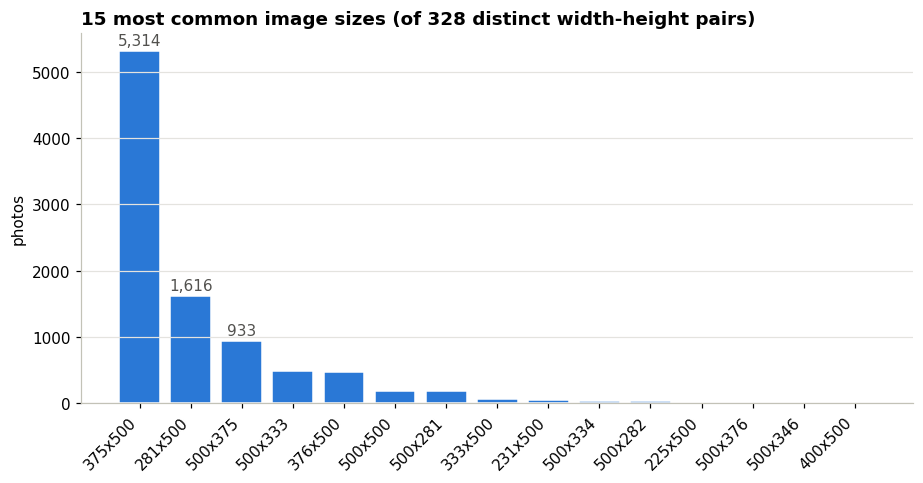

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
top15 = dim_counts.head(15)
labels = [f"{w}x{h}" for w, h in top15.index]
ax.bar(np.arange(len(top15)), top15.values, color="#2a78d6", edgecolor="white", linewidth=1)
ax.set_xticks(np.arange(len(top15)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("photos")
ax.set_title(f"15 most common image sizes (of {len(dim_counts)} distinct width-height pairs)")
for i, v in enumerate(top15.values[:3]):
    ax.annotate(f"{v:,}", (i, v), ha="center", va="bottom", xytext=(0, 2), textcoords="offset points", color="#52514e")
fig.tight_layout()
plt.show()

This shows that in the current sample, all images have longest side 500 except for three images. Uploading to iNaturalist resizes the images to have longest side 500px unless both sides are already smaller than 500px.

In [ ]:
print("Longest side (px) frequencies:")
longest = df["longest_side"].value_counts().sort_index(ascending=False)
print(longest.head(10).to_string())
print("...")
n_500 = int((df["longest_side"] == 500).sum())
print(f"\nPhotos with longest side exactly 500 px: {n_500} of {len(df)} ({n_500 / len(df):.2%})")
print(f"Photos with longest side  > 500 px: {int((df['longest_side'] > 500).sum())}")
print(f"Photos with longest side  < 500 px: {int((df['longest_side'] < 500).sum())}")

Longest side (px) frequencies:
longest_side
500    9997
412       1
366       1
312       1
...

Photos with longest side exactly 500 px: 9997 of 10000 (99.97%)
Photos with longest side  > 500 px: 0
Photos with longest side  < 500 px: 3


In [ ]:
small = df[df["longest_side"] != 500]
print(f"Photos whose longest side is not 500 px: {len(small)}")
print("By pool:", small["label"].value_counts().to_dict())
small[["label", "scientific_name", "width", "height", "longest_side", "photo_url"]].sort_values("longest_side")

Photos whose longest side is not 500 px: 3
By pool: {'introduced': 2, 'native': 1}


,label,scientific_name,width,height,longest_side,photo_url
9170,native,Veratrum californicum,312,281,312,https://inaturalist-open-data.s3.amazonaws.com...
3570,introduced,Cosmos sulphureus,366,307,366,https://inaturalist-open-data.s3.amazonaws.com...
3656,introduced,Nicotiana glauca,265,412,412,https://inaturalist-open-data.s3.amazonaws.com...


We count photos with portrait vs. landscape vs. square orientiation:

In [ ]:
ORIENT_ORDER = ["portrait", "landscape", "square"]
orient_overall = df["orientation"].value_counts().reindex(ORIENT_ORDER)
orient_by_label = pd.crosstab(df["label"], df["orientation"]).reindex(index=LABEL_ORDER, columns=ORIENT_ORDER)

summary = pd.DataFrame({"photos": orient_overall, "share": (orient_overall / len(df)).map("{:.1%}".format)})
print("Overall:")
display(summary)
print("By pool (counts):")
display(orient_by_label)
print("By pool (share within pool):")
display(orient_by_label.div(orient_by_label.sum(axis=1), axis=0).map("{:.1%}".format))

Overall:


,photos,share
orientation,,
portrait,7847,78.5%
landscape,1961,19.6%
square,192,1.9%


By pool (counts):


orientation,portrait,landscape,square
label,,,
native,3878,1006,116
introduced,3969,955,76


By pool (share within pool):


orientation,portrait,landscape,square
label,,,
native,77.6%,20.1%,2.3%
introduced,79.4%,19.1%,1.5%


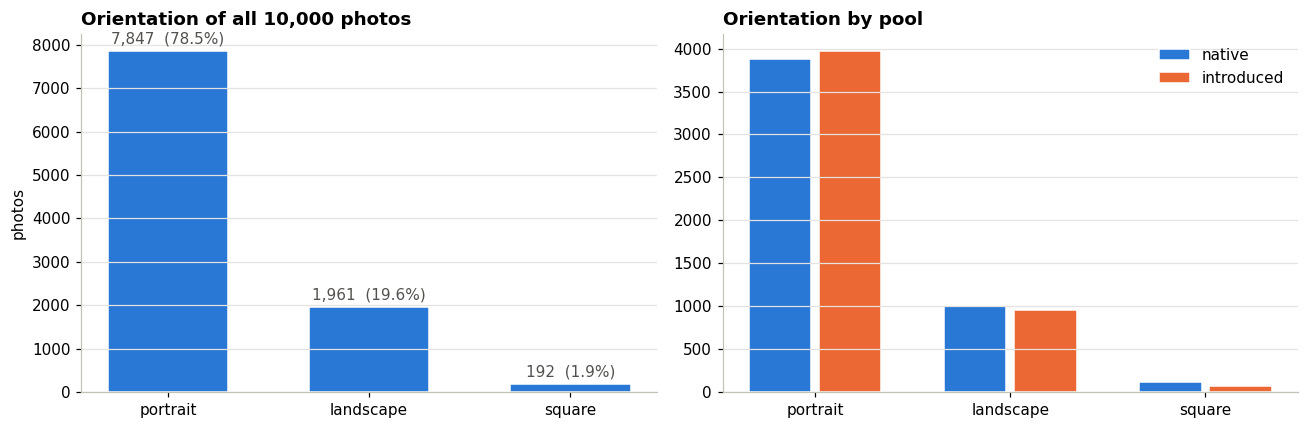

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.bar(ORIENT_ORDER, orient_overall.values, color="#2a78d6", edgecolor="white", linewidth=1, width=0.6)
for i, v in enumerate(orient_overall.values):
    ax.annotate(f"{v:,}  ({v / len(df):.1%})", (i, v), ha="center", va="bottom",
                xytext=(0, 3), textcoords="offset points", color="#52514e")
ax.set_ylabel("photos")
ax.set_title("Orientation of all 10,000 photos")

ax = axes[1]
x = np.arange(len(ORIENT_ORDER))
w = 0.36
for i, lab in enumerate(LABEL_ORDER):
    ax.bar(x + (i - 0.5) * w, orient_by_label.loc[lab].values, width=w - 0.04,
           color=LABEL_COLOR[lab], edgecolor="white", linewidth=1, label=lab)
ax.set_xticks(x)
ax.set_xticklabels(ORIENT_ORDER)
ax.set_title("Orientation by pool")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

We plot the aspect ratio and observe that most photos are 3:4 portrait or 4:3 landscape:

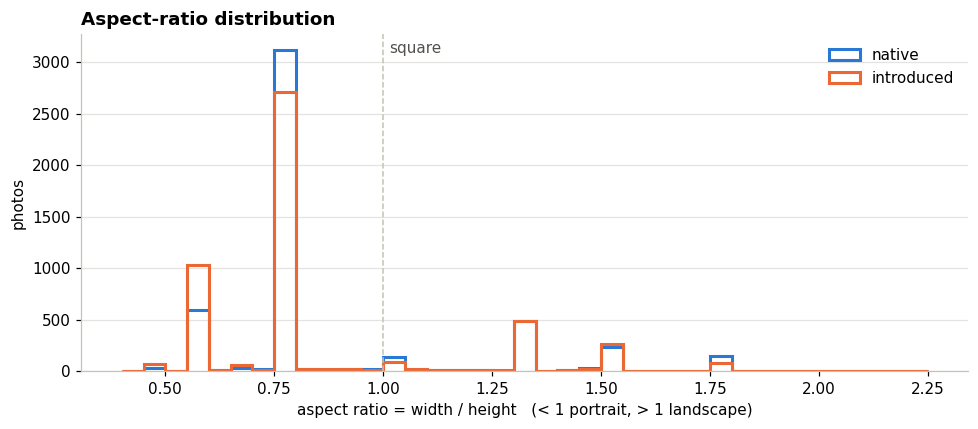

Most common aspect ratios (rounded to 2 dp):
aspect_ratio
0.75    5796
0.56    1623
1.33     957
1.50     520
1.00     197
1.78     190
0.67      75
0.46      62


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0.4, 2.3, 0.05)
for lab in LABEL_ORDER:
    ax.hist(df.loc[df["label"] == lab, "aspect_ratio"], bins=bins, histtype="step",
            linewidth=2, color=LABEL_COLOR[lab], label=lab)
ax.axvline(1, color="#c3c2b7", linewidth=1, linestyle="--")
ax.annotate("square", xy=(1, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points", color="#52514e")
ax.set_xlabel("aspect ratio = width / height   (< 1 portrait, > 1 landscape)")
ax.set_ylabel("photos")
ax.set_title("Aspect-ratio distribution")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print("Most common aspect ratios (rounded to 2 dp):")
print(df["aspect_ratio"].round(2).value_counts().head(8).to_string())